<a href="https://colab.research.google.com/github/sathishvaddepally07/ML_LAB_2026-27/blob/main/Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

----- LOGISTIC REGRESSION RESULTS -----
Accuracy: 98.6 %

Confusion Matrix:
[[52  1]
 [ 1 89]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143



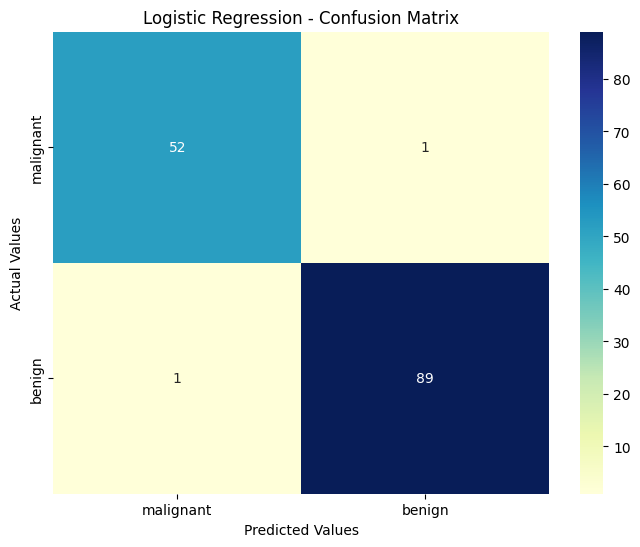

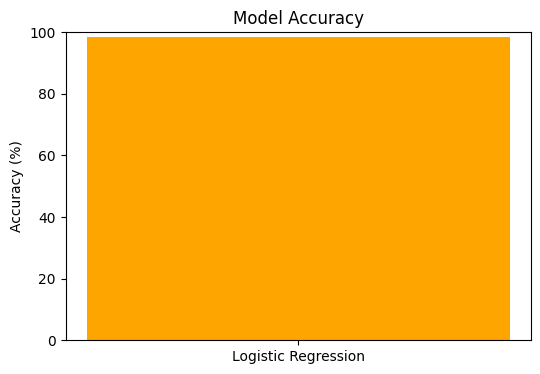

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

\
data = load_breast_cancer()

X = data.data
y = data.target


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


model = LogisticRegression(
    solver='lbfgs',
    max_iter=2000
)


model.fit(X_train, y_train)


y_pred = model.predict(X_test)


accuracy = accuracy_score(y_test, y_pred)

print("----- LOGISTIC REGRESSION RESULTS -----")

print("Accuracy:", round(accuracy * 100, 2), "%")


cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))


plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()


plt.figure(figsize=(6, 4))

plt.bar(
    ["Logistic Regression"],
    [accuracy * 100],
    color='orange',
    width=0.4
)

plt.title("Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()